# MSE802 Assessment 2 — Task 1: Entanglement Demonstration (Cirq + Quokka)

| Item | Detail |
|---|---|
| Course | MSE802 Quantum Computing — Assessment 2 (Group Project) |
| Learning outcome | LO2 — design and create quantum circuits to run on a quantum computer |
| Shots | 1000 per run |

**Task question:** *Create an entangled Bell state using Cirq and run the system on the Quokka device.*

$$|\psi\rangle = \frac{1}{\sqrt{2}}\left(|00\rangle + |11\rangle\right)$$

### Running in Google Colab?
Run the next cell first. In Colab it downloads the project from GitHub, installs the packages and moves into this task's folder. In VS Code / Jupyter it does nothing.

In [1]:
# ---------- Google Colab bootstrap (skipped automatically on your own PC) ----------
import os, sys, subprocess
from pathlib import Path
REPO_URL = "https://github.com/anishnz/quantumcomputing_YB_Anish.git"
REPO_DIR = Path("/content/quantumcomputing_YB_Anish")
TASK_DIR = "Task_1_Bell_State"
if "google.colab" in sys.modules and not (Path.cwd().parent / "common").exists():
    if not REPO_DIR.exists():                         # 1. download the project from GitHub
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO_DIR)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",   # 2. install quantum packages
                    "cirq-core", "qiskit", "qiskit-aer", "pylatexenc"], check=True)
    os.chdir(REPO_DIR / "Assignment_2_Quantum" / TASK_DIR)     # 3. work inside this task's folder
print("Working folder:", Path.cwd())

Working folder: /home/claude/Assignment_2_Quantum/Task_1_Bell_State


## 1. What are we trying to show? (Objective)

We build the Bell state $|\Phi^+\rangle$ with two qubits, run it 1000 times on Quokka and check that:

1. the only outcomes are **00** and **11** (the two qubits always agree), and
2. each of these appears about **50 %** of the time.

## 2. Why does H followed by CNOT make this state? (Theory)

| Step | Gate | State of the two qubits $|q_1 q_0\rangle$ written as $|q_0 q_1\rangle$ |
|---|---|---|
| 0 | start | $|00\rangle$ |
| 1 | $H$ on $q_0$ | $\frac{1}{\sqrt2}(|0\rangle+|1\rangle)\otimes|0\rangle = \frac{1}{\sqrt2}(|00\rangle+|10\rangle)$ |
| 2 | CNOT ($q_0$ control, $q_1$ target) | $\frac{1}{\sqrt2}(|00\rangle+|11\rangle)$ |

The Hadamard matrix and CNOT matrix are

$$H=\frac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix},\qquad
\mathrm{CNOT}=\begin{pmatrix}1&0&0&0\\0&1&0&0\\0&0&0&1\\0&0&1&0\end{pmatrix}$$

By the Born rule, $P(00)=|1/\sqrt2|^2=0.5$, $P(11)=0.5$, $P(01)=P(10)=0$.
The state cannot be written as (state of $q_0$) $\otimes$ (state of $q_1$), so it is **entangled**.

## 3. Set-up: imports and the shared Quokka helper

In [2]:
# ---------- standard imports ----------
import sys                                   # lets us add the shared 'common' folder to the import path
from pathlib import Path                     # works the same on Windows (VS Code) and Linux
import numpy as np                           # maths on arrays (state vector amplitudes)
import matplotlib.pyplot as plt              # charts
import cirq                                  # Google's quantum circuit library (required by the task)

# ---------- shared helper written by the team ----------
sys.path.insert(0, str(Path.cwd().parent / "common"))   # ../common holds quokka_helper.py
import quokka_helper as qh                   # clean QASM, send to Quokka, fallback, counts, plots

SHOTS = 1000                                 # number of repetitions agreed by the group
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)  # evidence folder for this task
print("Cirq version:", cirq.__version__)
print("Quokka status:", qh.quokka_status())  # 'online' or the reason it is offline

Cirq version: 1.7.0


Quokka status: offline (Quokka endpoint is offline (HTTP 404, ERR_NGROK_3200))


## 4. Build the Bell-state circuit in Cirq

In [3]:
q0, q1 = cirq.LineQubit.range(2)             # two qubits on a line: q(0) and q(1), both start in |0>

bell = cirq.Circuit(
    cirq.H(q0),                              # Hadamard: puts q0 into (|0> + |1>)/sqrt(2)
    cirq.CNOT(q0, q1),                       # CNOT: flips q1 only when q0 is 1 -> links (entangles) the qubits
    cirq.measure(q0, q1, key="c"),           # measure both qubits into one 2-bit register called 'c'
)
print(bell)                                  # text drawing of the circuit

0: ───H───@───M('c')───
          │   │
1: ───────X───M────────


## 5. Check the theory before using hardware (ideal state vector)

Cirq's simulator gives the exact amplitudes. This is our **theoretical prediction** that the Quokka results will be compared with.

In [4]:
no_measure = bell[:-1]                                   # same circuit without the final measurement
state = cirq.Simulator().simulate(no_measure).final_state_vector   # exact amplitudes
for index, amp in enumerate(state):                      # index 0..3 = |00>,|01>,|10>,|11> (q0 is left bit)
    label = format(index, "02b")
    print(f"|{label}>  amplitude = {np.round(amp, 4)}   probability = {abs(amp)**2:.3f}")

theory = {"00": 0.5, "01": 0.0, "10": 0.0, "11": 0.5}   # Born-rule probabilities (same in both bit orders)

|00>  amplitude = (0.707099974155426+0j)   probability = 0.500
|01>  amplitude = 0j   probability = 0.000
|10>  amplitude = 0j   probability = 0.000
|11>  amplitude = (0.707099974155426+0j)   probability = 0.500


## 6. Convert the Cirq circuit to OpenQASM 2.0 (the language Quokka understands)

In [5]:
raw_qasm = cirq.qasm(bell)                   # Cirq writes standard OpenQASM 2.0 text
quokka_qasm = qh.clean_qasm(raw_qasm)        # remove comments and the qelib1.inc line (not on Quokka)
print(quokka_qasm)
_ = (RESULTS / "task1_bell_state.qasm").write_text(quokka_qasm)   # keep a copy as evidence

OPENQASM 2.0;
qreg q[2];
creg m_c[2];
h q[0];
cx q[0],q[1];
measure q[0] -> m_c[0];
measure q[1] -> m_c[1];



## 7. Run on the Quokka device (1000 shots)

`qh.run_qasm` posts the script to `http://quokka1.quokkacomputing.com/qsim/qasm`. If Quokka is offline, the **same script** runs on a local simulator and the result is labelled **LOCAL SIMULATOR**, so it is never reported as Quokka data.

In [6]:
run = qh.run_qasm(quokka_qasm, shots=SHOTS, label="task1_bell_quokka", save_dir=RESULTS)

print("Source of results :", run["source"])
if run["quokka_error"]:
    print("Why not Quokka    :", run["quokka_error"])
print("Shots received    :", run["shots_received"])
print("Counts            :", run["counts"])
print("Run time (s)      :", run["seconds"])

Source of results : LOCAL SIMULATOR (Qiskit Aer) - Quokka was not reachable
Why not Quokka    : Quokka endpoint is offline (HTTP 404, ERR_NGROK_3200)
Shots received    : 1000
Counts            : {'00': 508, '11': 492}
Run time (s)      : 0.7617


## 8. Results table: theory versus measurement

In [7]:
import pandas as pd                                      # neat tables

measured = run["probs"]                                  # counts / 1000
table = pd.DataFrame({
    "Outcome": list(theory.keys()),
    "Theory P": [theory[k] for k in theory],
    "Counts (of 1000)": [run["counts"].get(k, 0) for k in theory],
    "Measured P": [round(measured.get(k, 0), 3) for k in theory],
})
table["Difference"] = (table["Measured P"] - table["Theory P"]).round(3)
display(table)

tvd = qh.total_variation_distance(theory, measured)      # 0 = perfect agreement
same = run["counts"].get("00", 0) + run["counts"].get("11", 0)
print(f"Correlated shots (00 or 11): {same} of {run['shots_received']}  ({same/run['shots_received']:.1%})")
print(f"Total variation distance (theory vs measured): {tvd:.4f}")
table.to_csv(RESULTS / "task1_results_table.csv", index=False)

,Outcome,Theory P,Counts (of 1000),Measured P,Difference
0,00,0.5,508,0.508,0.008
1,01,0.0,0,0.000,0.000
2,10,0.0,0,0.000,0.000
3,11,0.5,492,0.492,-0.008


Correlated shots (00 or 11): 1000 of 1000  (100.0%)
Total variation distance (theory vs measured): 0.0080


## 9. Histogram

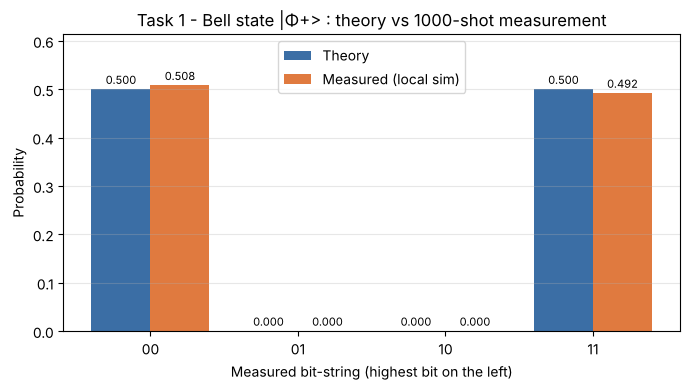

In [8]:
fig = qh.plot_comparison(
    {"Theory": theory, "Measured (" + ("Quokka" if run["source"] == qh.SOURCE_QUOKKA else "local sim") + ")": measured},
    title="Task 1 - Bell state |Φ+> : theory vs 1000-shot measurement",
    path=RESULTS / "task1_histogram.png")
plt.show()

## 10. Is 500/500 exactly what we should expect? (Statistical check)

With 1000 shots, the number of `00` results follows a binomial distribution with $p=0.5$:
standard deviation $=\sqrt{1000 \times 0.5 \times 0.5}\approx 15.8$.
So any count between about **468 and 532** (± 2 standard deviations) is normal random variation, not an error.

In [9]:
n00 = run["counts"].get("00", 0)                           # how many times we saw 00
sigma = np.sqrt(SHOTS * 0.5 * 0.5)                         # binomial standard deviation
z = (n00 - SHOTS * 0.5) / sigma                            # how many sigmas away from 500
print(f"00 count = {n00},  expected 500 ± {sigma:.1f},  z-score = {z:+.2f}")
print("Within normal shot noise (|z| < 2):", abs(z) < 2)

00 count = 508,  expected 500 ± 15.8,  z-score = +0.51
Within normal shot noise (|z| < 2): True


## 11. Conclusion

* The circuit **H → CNOT → measure** prepares $|\Phi^+\rangle=\frac{1}{\sqrt2}(|00\rangle+|11\rangle)$.
* The measurement shows only correlated outcomes (00 and 11) with roughly equal frequency, which is the signature of this Bell state.
* Small departures from 500/500 are explained by binomial shot noise (see Section 10).
* The full discussion, including why Quokka behaves almost like an ideal device, is in the group report (Task 1 section).